# Boosting I - AdaBoost & Gradient Boosting
### Which streaming-service customers will churn? - learning from your own mistakes, one round at a time

**Dataset (provided separately):** `streaming_customers.csv` - 8000 subscribers of a video-streaming app:
- Features: `tenure_months`, `monthly_bill_rs`, `support_calls_3m`, `late_payments_6m`, `devices_linked`, `genres_watched`, `discount_active`, `app_crashes_last_month`
- `churned` (0/1) - did the customer cancel? (**classification** target)
- `monthly_watch_hours` - hours the customer watches per month (**regression** target)

**What this notebook covers (theory in markdown, then code):**
1. Boosting vs bagging - the big idea of **sequential learning**
2. **AdaBoost** - re-weighting the examples the last model got wrong (built from scratch, then sklearn)
3. **Gradient Boosting** - fitting each new tree to the leftover errors (residuals), built from scratch, then sklearn
4. Hyperparameters: `n_estimators`, `learning_rate`, `max_depth` - and how to tune them
5. Classification AND regression, compared against last class's **Random Forest**
6. Bagging vs boosting - a summary note

Two code cells hide a small deliberate bug marked `# FIX ME`, each with a hint. Find and fix both.

In [33]:
import os
data_paths = {}
for base in ['/kaggle/input', '.']:            # Kaggle first, then the current folder (for running locally)
    if os.path.exists(base):
        for dirname, _, filenames in os.walk(base):
            for filename in filenames:
                if 'streaming_customers' in filename and filename.endswith('.csv'):
                    data_paths['customers'] = os.path.join(dirname, filename)
print(data_paths)
# If this prints an empty dict: click 'Add Input' and attach streaming_customers.csv first

{'customers': '/kaggle/input/datasets/manikantaarigela1/dtreaming-coustemers/streaming_customers.csv'}


In [34]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              AdaBoostClassifier, AdaBoostRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor)
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

sns.set_style('whitegrid')

---
# Part 1 - Load, understand and split the data

## Theory
Same routine: look at the data, check for missing values, split into a **training set** (models learn from it) and a **test set** (hidden, used for the honest final check). Tree-based models, boosted or not, do not need feature scaling.

Notice the churn rate is about 31% - so a lazy model that says "nobody churns" is right about 69% of the time. As always, we will look at more than accuracy.

In [35]:
assert 'customers' in data_paths, "Attach streaming_customers.csv via Add Input first."
df = pd.read_csv(data_paths['customers'])
print(df.shape)
df.head()

(8000, 10)


,tenure_months,monthly_bill_rs,support_calls_3m,late_payments_6m,devices_linked,genres_watched,discount_active,app_crashes_last_month,churned,monthly_watch_hours
0,24,675.0,0,1,5,5,0,0,0,38.5
1,53,473.0,1,0,5,4,1,1,0,37.2
2,18,190.0,2,2,2,3,0,2,1,23.0
3,35,589.0,2,0,5,6,0,1,1,47.2
4,40,297.0,0,1,2,3,1,1,0,21.5


In [36]:
print(df.isnull().sum().sum(), 'missing values')
print('Churn rate:', round(df['churned'].mean(), 3))
df.describe().round(1)

0 missing values
Churn rate: 0.312


,tenure_months,monthly_bill_rs,support_calls_3m,late_payments_6m,devices_linked,genres_watched,discount_active,app_crashes_last_month,churned,monthly_watch_hours
count,8000.0,8000.0,8000.0,8000.0,8000.0,8000.0,8000.0,8000.0,8000.0,8000.0
mean,27.7,421.1,1.3,0.6,3.0,5.0,0.5,1.0,0.3,33.5
std,18.1,140.9,1.1,0.8,1.4,2.0,0.5,1.0,0.5,9.0
min,1.0,149.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,6.5
25%,13.0,308.0,0.0,0.0,2.0,4.0,0.0,0.0,0.0,27.1
50%,24.0,418.0,1.0,0.0,3.0,5.0,0.0,1.0,0.0,32.7
75%,38.0,534.0,2.0,1.0,4.0,6.0,1.0,2.0,1.0,39.0
max,72.0,802.0,8.0,5.0,5.0,12.0,1.0,6.0,1.0,65.8


In [37]:
feature_cols = ['tenure_months', 'monthly_bill_rs', 'support_calls_3m', 'late_payments_6m',
                'devices_linked', 'genres_watched', 'discount_active', 'app_crashes_last_month']
X = df[feature_cols].values
y = df['churned'].values                # classification target
y_hours = df['monthly_watch_hours'].values   # regression target (used in Part 5) - NOT a churn feature

X_train, X_test, y_train, y_test, yh_train, yh_test = train_test_split(
    X, y, y_hours, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape[0], '| Test:', X_test.shape[0])

Train: 6400 | Test: 1600


## Metrics toolkit (reminder)
Positive = "customer churns". **TP** predicted churn and did; **FP** predicted churn but stayed (wasted retention offer); **FN** predicted stay but churned (a lost customer we never tried to save); **TN** predicted stay and stayed. Accuracy, Precision = TP/(TP+FP), Recall = TP/(TP+FN), Specificity = TN/(TN+FP), F1, and **AUC** (how well the model ranks churners above stayers across every threshold).

In [38]:
def evaluate(name, y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    r = {'model': name,
         'accuracy': (tp + tn) / (tp + tn + fp + fn),
         'precision': tp / (tp + fp) if (tp + fp) else 0.0,
         'recall': tp / (tp + fn) if (tp + fn) else 0.0,
         'specificity': tn / (tn + fp) if (tn + fp) else 0.0}
    p, rec = r['precision'], r['recall']
    r['f1'] = 2 * p * rec / (p + rec) if (p + rec) else 0.0
    if y_prob is not None:
        r['auc'] = roc_auc_score(y_true, y_prob)
    return r

---
# Part 2 - Boosting vs Bagging: the big idea

## 2.1 Quick recap - bagging and random forests (last class)
Bagging trains many deep trees **independently and in parallel**, each on a different bootstrap sample, then lets them vote. The trees never talk to each other. It works by **cancelling variance** (overfitting noise).

## 2.2 Boosting - a completely different way to build a team
**Boosting trains models one after another (sequentially), and each new model focuses on what the previous ones got wrong.** The final answer is a weighted combination of all of them.

**Analogy 1 - revision after mock tests:** you take a mock test, see which questions you got wrong, and spend your next revision session mostly on THOSE questions. Take another mock test, find the new weak spots, repeat. After ten rounds you are strong everywhere, even though no single revision session was impressive. Bagging, by contrast, is ten students each studying a different photocopy of the notes and voting on the answer.

**Analogy 2 - a relay of tutors:** tutor 1 teaches the class. Tutor 2 is told which students tutor 1 failed to reach and concentrates on them. Tutor 3 concentrates on whoever is still lost. Each tutor is only mediocre alone; the chain is excellent.

```
BAGGING (parallel, independent)          BOOSTING (sequential, each fixes the last)

 data -> sample 1 -> tree 1 --+           data -> tree 1  (finds the easy patterns)
 data -> sample 2 -> tree 2 --+--> VOTE            |  its mistakes get extra attention
 data -> sample 3 -> tree 3 --+                    v
 (trees never talk to each other)           tree 2  (fixes tree 1's mistakes)
                                                   |
                                                   v
                                            tree 3  (fixes what is STILL wrong) ...
                                                   |
                                                   v
                                            weighted SUM of all the trees
```

## 2.3 Weak learners
Boosting uses **weak learners** - models only slightly better than guessing. The classic one is a **decision stump**: a tree with depth 1, a single yes/no question ("is `late_payments_6m` >= 1?"). One stump is poor; hundreds of stumps, each correcting the last, are powerful.

**Analogy:** a student who is just a little better than a coin flip on any one question - but after fifty rounds of focused correction, becomes an expert.

## 2.4 Bagging vs Boosting - side by side

| | **Bagging / Random Forest** | **Boosting (AdaBoost, Gradient Boosting)** |
|---|---|---|
| How models are built | **in parallel**, independently | **one after another**, each depends on the previous |
| What each model sees | a random bootstrap sample | the data re-weighted (AdaBoost) or the leftover errors (Gradient Boosting) |
| Typical base learner | **deep** trees (low bias, high variance) | **shallow** trees / stumps (high bias, low variance) |
| How predictions combine | equal vote / plain average | **weighted** sum - better models get more say |
| What it mainly fixes | **variance** (overfitting noise) | **bias** (underfitting) - and, with care, variance too |
| Speed | easy to parallelise (`n_jobs`) | inherently sequential - slower to train |
| Overfitting risk | low - more trees rarely hurt | can overfit if you run too many rounds or take big steps |
| Key knobs | `n_estimators`, `max_features`, `max_depth` | `n_estimators`, **`learning_rate`**, `max_depth` |

---
# Part 3 - AdaBoost (Adaptive Boosting)

## 3.1 The idea: re-weighting
1. Give every training customer an equal **weight** (importance): 1/N each.
2. Train a weak learner (a stump) on the **weighted** data - it tries harder to get high-weight customers right.
3. Measure its **weighted error** `err` (the total weight of the customers it got wrong).
4. Give the stump a **say** in the final vote: `alpha = 0.5 x ln((1 - err) / err)`.
5. **Increase the weight of customers it got wrong, decrease the weight of those it got right**, and re-normalise so the weights sum to 1.
6. Repeat. The next stump is forced to focus on the hard cases.
7. Final prediction = **weighted vote** of all stumps (each stump's vote multiplied by its alpha).

The weight update: `w_new = w_old x exp(-alpha)` if the stump was right, `w_old x exp(+alpha)` if it was wrong (then re-normalise).

**Analogy - mock-test revision:** the questions you got wrong are highlighted in red and appear more often in the next practice set. And how seriously you take each session's lesson depends on how well it went (alpha).

**What does alpha (a stump's "say") look like?**

| weighted error | alpha | meaning |
|---|---|---|
| 0.10 | 1.10 | very accurate - a loud voice in the vote |
| 0.20 | 0.69 | good |
| 0.30 | 0.42 | decent |
| 0.50 | 0.00 | no better than a coin flip - no say at all |
| above 0.50 | negative | worse than guessing - its vote is flipped |

**Worked example:** 10 customers, equal weights 0.1 each. A stump gets 2 wrong, so `err = 0.2` and `alpha = 0.5 x ln(0.8/0.2) = 0.693`.
```
wrong ones:   0.1 x e^(+0.693) = 0.1 x 2   = 0.20  (each)   -> 2 x 0.20 = 0.40 total
right ones:   0.1 x e^(-0.693) = 0.1 x 0.5 = 0.05  (each)   -> 8 x 0.05 = 0.40 total
re-normalise (divide by 0.80):  wrong = 0.25 each (0.50 total), right = 0.0625 each (0.50 total)
```
After the update, the two mistakes carry **half of all the weight**, so the next stump simply cannot ignore them. (This 50% is not a coincidence - alpha is designed to do exactly this.)

## Implementation 1 - check the worked example in code

In [39]:
n = 10
w = np.ones(n) / n                     # equal weights: 0.1 each
wrong = np.array([True, True] + [False] * 8)

err = w[wrong].sum()
alpha = 0.5 * np.log((1 - err) / err)
w_new = np.where(wrong, w * np.exp(alpha), w * np.exp(-alpha))
w_new = w_new / w_new.sum()

print(f'err = {err:.2f}, alpha = {alpha:.3f}')
print('new weight of each wrong customer:', round(w_new[wrong][0], 4))
print('new weight of each right customer:', round(w_new[~wrong][0], 4))
print('total weight now carried by the 2 mistakes:', round(w_new[wrong].sum(), 3))

err = 0.20, alpha = 0.693
new weight of each wrong customer: 0.25
new weight of each right customer: 0.0625
total weight now carried by the 2 mistakes: 0.5


## Implementation 2 - AdaBoost from scratch with decision stumps
We train 50 stumps. AdaBoost's maths uses labels **-1 / +1**, so we convert first. Decision trees accept per-row `sample_weight`, which is exactly how a stump "pays more attention" to heavy customers.

For the first 3 rounds we print the total weight carried by the customers the stump got wrong, **before** and **after** the update. After a correct update that number must go **up** (to exactly 0.5).

In [40]:
y_train_pm = np.where(y_train == 1, 1, -1)      # AdaBoost uses -1/+1 labels
y_test_pm = np.where(y_test == 1, 1, -1)

n_train = len(y_train_pm)
w = np.ones(n_train) / n_train                  # start: every customer equally important
n_rounds = 50
alphas, stumps = [], []
test_scores = np.zeros(len(y_test_pm))
staged_acc = []                                 # test accuracy after each round

for t in range(n_rounds):
    stump = DecisionTreeClassifier(max_depth=1, random_state=0)
    stump.fit(X_train, y_train_pm, sample_weight=w)         # trains on the WEIGHTED data
    pred = stump.predict(X_train)

    wrong = (pred != y_train_pm)
    err = w[wrong].sum() / w.sum()                           # weighted error
    alpha = 0.5 * np.log((1 - err) / (err + 1e-10))          # this stump's "say" in the final vote

    share_before = w[wrong].sum()
    # FIX ME: the update direction is backwards. A customer the stump got WRONG must get a HEAVIER weight,
    # and one it got RIGHT a lighter weight. As written, the mistakes get lighter instead.
    # Hint: look at the "before -> after" printout - the weight on mistakes should go UP (to 0.5), not down.
    w = w * np.exp(-alpha * y_train_pm * pred)
    w = w / w.sum()                                          # re-normalise so weights sum to 1
    share_after = w[wrong].sum()

    if t < 3:
        print(f'Round {t+1}: err={err:.3f}, alpha={alpha:.3f} | weight on mistakes: {share_before:.3f} -> {share_after:.3f}')

    alphas.append(alpha); stumps.append(stump)
    test_scores += alpha * stump.predict(X_test)             # add this stump's weighted vote
    staged_acc.append((np.where(test_scores >= 0, 1, -1) == y_test_pm).mean())

print(f'\nTest accuracy after 1 stump:   {staged_acc[0]:.3f}')
print(f'Test accuracy after {n_rounds} stumps:  {staged_acc[-1]:.3f}')

Round 1: err=0.281, alpha=0.470 | weight on mistakes: 0.281 -> 0.500
Round 2: err=0.366, alpha=0.275 | weight on mistakes: 0.366 -> 0.500
Round 3: err=0.389, alpha=0.225 | weight on mistakes: 0.389 -> 0.500

Test accuracy after 1 stump:   0.716
Test accuracy after 50 stumps:  0.776


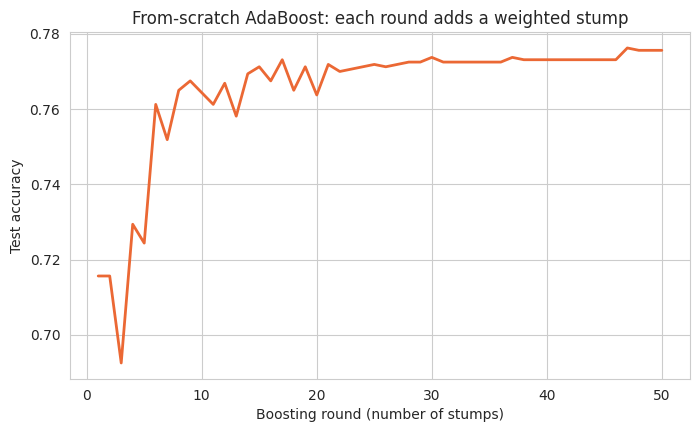

In [41]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, n_rounds + 1), staged_acc, color='#eb6834', linewidth=2)
plt.xlabel('Boosting round (number of stumps)')
plt.ylabel('Test accuracy')
plt.title('From-scratch AdaBoost: each round adds a weighted stump')
plt.show()

**What to expect once fixed:** the weight on mistakes jumps to 0.500 every round, and test accuracy climbs well above the single stump as the stumps cover each other's blind spots. If accuracy stays flat or the printout shows the weight falling, the update direction is still wrong.

## Implementation 3 - AdaBoost with scikit-learn
`AdaBoostClassifier` does exactly this (it uses a closely related version called SAMME, and has a `learning_rate` that shrinks every stump's alpha). By default the weak learner is a stump (`max_depth=1`).

In [42]:
ada = AdaBoostClassifier(n_estimators=50, random_state=0).fit(X_train, y_train)
print('sklearn AdaBoost (50 stumps) test accuracy:', round(ada.score(X_test, y_test), 3))
print('Our from-scratch version      test accuracy:', round(staged_acc[-1], 3))
print('(Once you have fixed the AdaBoost bug above, these two should be very close - sklearn uses a slightly different, closely related formula.)')

single_stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_train, y_train)
print('\nA single stump on its own:', round(single_stump.score(X_test, y_test), 3))

sklearn AdaBoost (50 stumps) test accuracy: 0.776
Our from-scratch version      test accuracy: 0.776
(Once you have fixed the AdaBoost bug above, these two should be very close - sklearn uses a slightly different, closely related formula.)

A single stump on its own: 0.716


---
# Part 4 - Gradient Boosting

## 4.1 The idea: fit the leftover errors (residuals)
AdaBoost fixes mistakes by re-weighting rows. **Gradient Boosting fixes them by predicting the error directly.**

1. Start with a very simple prediction for everyone - for regression, just the **average** of the target.
2. Compute each customer's **residual** = actual - current prediction (how far off we still are).
3. Train a small tree to **predict those residuals** (i.e. learn the pattern in our mistakes).
4. Add a **fraction** of that tree's output to the current prediction: `new prediction = old prediction + learning_rate x tree output`.
5. Compute fresh residuals, repeat.

```
F0 = average of y
for each round m:
    residuals = y - F(current prediction)
    h_m       = small tree trained to predict the residuals
    F         = F + learning_rate x h_m
Final prediction = F0 + learning_rate x (h_1 + h_2 + ... + h_M)
```

**Analogy - golf:** your first shot lands somewhere (the starting guess). The distance still left to the hole is the **residual**. Your next shot is aimed at closing exactly that remaining gap, and the one after that at whatever gap is left - you do not try to hole it in one swing.

**Analogy - painting a wall in thin coats:** each coat (tree) fixes a bit of what is still uneven. Many thin coats give a smooth finish; one thick coat drips and overshoots. That is the **learning rate**.

## 4.2 Why is it called "GRADIENT" boosting?
For squared-error loss `L = 1/2 (y - F)^2`, the **negative gradient** of the loss with respect to the prediction is exactly `y - F`: the residual. So fitting a tree to the residuals is the same as taking **a gradient-descent step, but in the space of functions** - each new tree is one step downhill on the loss (remember gradient descent from the regression classes). For other losses (like log loss in classification) the trees fit the negative gradient of THAT loss, called the **pseudo-residuals**. Same recipe, different loss.

## 4.3 Worked example (regression)
Four customers with watch-hours `[10, 14, 20, 24]`.
```
F0 = average = 17                       residuals = [-7, -3, +3, +7]
A tiny tree splits them into {first two} and {last two}, predicting the average residual in each group:
   left group: (-7 + -3)/2 = -5     right group: (3 + 7)/2 = +5
With learning_rate = 0.5:   F1 = 17 + 0.5 x [-5, -5, +5, +5] = [14.5, 14.5, 19.5, 19.5]
New residuals = [10-14.5, 14-14.5, 20-19.5, 24-19.5] = [-4.5, -0.5, +0.5, +4.5]
```
The errors shrank from [7, 3, 3, 7] to [4.5, 0.5, 0.5, 4.5] in one round, and another round would shrink them further. The code checks this.

## 4.4 Gradient boosting for classification
Same machinery, applied to **log-odds** (the same quantity logistic regression models): start from the log-odds of the overall churn rate, let each tree fit the pseudo-residuals `y - p` (actual 0/1 minus the current predicted probability), accumulate, and finally convert to a probability with the **sigmoid**.

## Implementation 1 - check the worked example

In [43]:
x_demo = np.array([[1], [2], [3], [4]])
y_demo = np.array([10, 14, 20, 24])

F0 = y_demo.mean()
resid = y_demo - F0
tiny_tree = DecisionTreeRegressor(max_depth=1).fit(x_demo, resid)    # a stump trained on the residuals
step = tiny_tree.predict(x_demo)

F1 = F0 + 0.5 * step
print('F0:', F0, '| residuals:', resid)
print('tree output:', step)
print('F1:', F1, '| new residuals:', y_demo - F1)

F0: 17.0 | residuals: [-7. -3.  3.  7.]
tree output: [-5. -5.  5.  5.]
F1: [14.5 14.5 19.5 19.5] | new residuals: [-4.5 -0.5  0.5  4.5]


In [44]:
# Classification flavour: where does a gradient-boosted classifier START?
p0 = y_train.mean()
F0_cls = np.log(p0 / (1 - p0))                       # log-odds of the overall churn rate
print(f'Overall churn rate p0 = {p0:.3f}  ->  starting log-odds F0 = {F0_cls:.3f}')
pseudo_resid = y_train - p0
print('Round-1 pseudo-residuals (y - p) take just two values:', np.unique(np.round(pseudo_resid, 3)))
print('Churners are "under-predicted" (+), stayers "over-predicted" (-): the first tree learns to separate them.')

Overall churn rate p0 = 0.312  ->  starting log-odds F0 = -0.792
Round-1 pseudo-residuals (y - p) take just two values: [-0.312  0.688]
Churners are "under-predicted" (+), stayers "over-predicted" (-): the first tree learns to separate them.


## Implementation 2 - Gradient Boosting Regressor from scratch
We predict `monthly_watch_hours` with 100 small trees (depth 2), learning rate 0.1. We track the **RMSE after every round** - it must fall steadily.

In [45]:
Xr_train, Xr_test = X_train, X_test
yr_train, yr_test = yh_train, yh_test

eta = 0.1                                            # learning rate
n_rounds = 100
F_train = np.full(len(yr_train), yr_train.mean())    # F0: start with the average for everyone
F_test = np.full(len(yr_test), yr_train.mean())

train_rmse, test_rmse = [], []
for m in range(n_rounds):
    # FIX ME: residuals must be ACTUAL minus CURRENT PREDICTION (y - F). The sign here is reversed,
    # so each tree pushes the predictions AWAY from the truth.
    # Hint: the RMSE printed below should FALL every round - if it grows, the direction is wrong.
    residuals =yr_train-F_train

    tree = DecisionTreeRegressor(max_depth=2, random_state=0).fit(Xr_train, residuals)   # predict the leftover error
    F_train += eta * tree.predict(Xr_train)                                              # add a FRACTION of its output
    F_test += eta * tree.predict(Xr_test)

    train_rmse.append(np.sqrt(np.mean((yr_train - F_train) ** 2)))
    test_rmse.append(np.sqrt(np.mean((yr_test - F_test) ** 2)))

for r in [1, 10, 50, 100]:
    print(f'After round {r:3d}:  train RMSE = {train_rmse[r-1]:8.2f} | test RMSE = {test_rmse[r-1]:8.2f}')

After round   1:  train RMSE =     8.54 | test RMSE =     8.37
After round  10:  train RMSE =     6.00 | test RMSE =     5.83
After round  50:  train RMSE =     3.79 | test RMSE =     3.79
After round 100:  train RMSE =     3.48 | test RMSE =     3.52


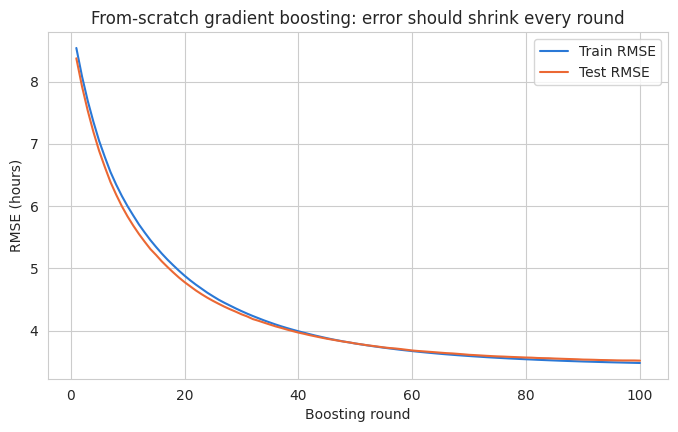

Our from-scratch test RMSE after 100 rounds: 3.52 hours
scikit-learn GradientBoostingRegressor:      3.52 hours   (should be very close once fixed)


In [46]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, n_rounds + 1), train_rmse, label='Train RMSE', color='#2a78d6')
plt.plot(range(1, n_rounds + 1), test_rmse, label='Test RMSE', color='#eb6834')
plt.xlabel('Boosting round')
plt.ylabel('RMSE (hours)')
plt.title('From-scratch gradient boosting: error should shrink every round')
plt.legend()
plt.show()

gb_check = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=0).fit(Xr_train, yr_train)
sk_rmse = np.sqrt(mean_squared_error(yr_test, gb_check.predict(Xr_test)))
print(f'Our from-scratch test RMSE after 100 rounds: {test_rmse[-1]:.2f} hours')
print(f'scikit-learn GradientBoostingRegressor:      {sk_rmse:.2f} hours   (should be very close once fixed)')

---
# Part 5 - AdaBoost vs Gradient Boosting vs Random Forest

## 5.1 Hyperparameters

| Hyperparameter | What it controls | Effect |
|---|---|---|
| `n_estimators` | number of boosting rounds (trees) | more rounds = fits more of the pattern, but too many can overfit |
| `learning_rate` | how big a step each round takes (a shrinkage factor on each tree's contribution) | small = careful, needs MORE rounds; large = fast but can overshoot and overfit |
| `max_depth` | complexity of each weak learner | keep it shallow: stumps for AdaBoost (default 1), ~3 for Gradient Boosting (default 3) |

(Also useful: `subsample` - train each tree on a random fraction of rows, called *stochastic gradient boosting*; and `min_samples_leaf`.)

**The key trade-off:** `learning_rate` and `n_estimators` pull against each other. Smaller steps need more rounds to reach the same place, but usually land somewhere slightly better.

## Implementation 1 - head-to-head on churn prediction

In [47]:
rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1).fit(X_train, y_train)
ada = AdaBoostClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=0).fit(X_train, y_train)
full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)

models = {'Single tree (no limits)': full_tree,
          'Random forest (200 trees)': rf,
          'AdaBoost (200 stumps)': ada,
          'Gradient boosting (100 trees, depth 3)': gb}

rows = []
for name, m in models.items():
    r = evaluate(name, y_test, m.predict(X_test), m.predict_proba(X_test)[:, 1])
    r['train_acc'] = m.score(X_train, y_train)
    r['gap'] = r['train_acc'] - r['accuracy']
    rows.append(r)
results = pd.DataFrame(rows).set_index('model')
results[['train_acc', 'accuracy', 'gap', 'precision', 'recall', 'specificity', 'f1', 'auc']].round(3)

,train_acc,accuracy,gap,precision,recall,specificity,f1,auc
model,,,,,,,,
Single tree (no limits),1.000,0.724,0.276,0.557,0.569,0.795,0.563,0.682
Random forest (200 trees),1.000,0.785,0.215,0.708,0.529,0.901,0.606,0.827
AdaBoost (200 stumps),0.784,0.783,0.001,0.694,0.545,0.891,0.611,0.828
"Gradient boosting (100 trees, depth 3)",0.820,0.798,0.022,0.761,0.511,0.927,0.612,0.847


Read the table: the single tree memorises (huge train-test gap). The forest and both boosters beat it clearly. The three ensembles end up close - boosting is usually competitive with, and often slightly better than, a random forest once tuned, but it is **not magic**: always compare on held-out data.

**Also notice:** recall is only about 0.5 for every model - with churners being a minority, the default 0.5 threshold lets about half of them slip through. If catching churners matters more than a few wasted retention offers, lower the threshold (the same dial from the logistic regression class) to trade precision for recall.

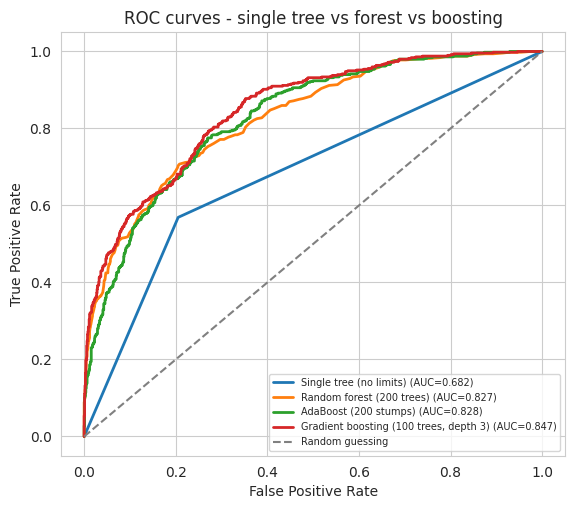

In [48]:
plt.figure(figsize=(6.5, 5.5))
for name, m in models.items():
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves - single tree vs forest vs boosting')
plt.legend(fontsize=7)
plt.show()

## Implementation 2 - how many rounds? Watch the learning curve
`staged_predict` lets us see the model's test accuracy after 1, 2, 3 ... rounds without retraining.

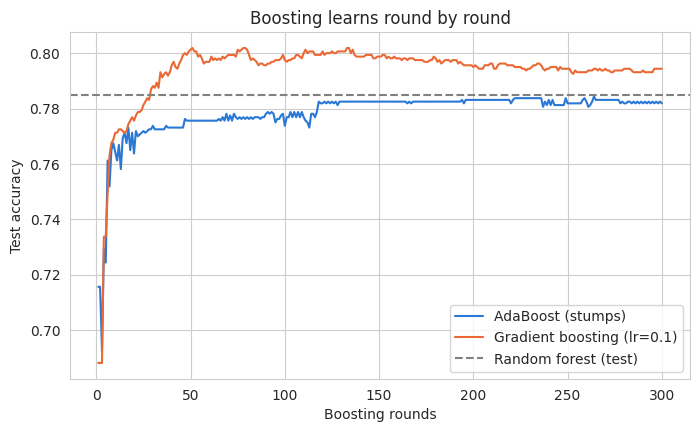

Gradient boosting peaks at round 51 with test accuracy 0.802


In [49]:
ada_big = AdaBoostClassifier(n_estimators=300, random_state=0).fit(X_train, y_train)
gb_big = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, random_state=0).fit(X_train, y_train)

ada_curve = [(p == y_test).mean() for p in ada_big.staged_predict(X_test)]
gb_curve = [(p == y_test).mean() for p in gb_big.staged_predict(X_test)]

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 301), ada_curve, label='AdaBoost (stumps)', color='#2a78d6')
plt.plot(range(1, 301), gb_curve, label='Gradient boosting (lr=0.1)', color='#eb6834')
plt.axhline(rf.score(X_test, y_test), color='gray', linestyle='--', label='Random forest (test)')
plt.xlabel('Boosting rounds')
plt.ylabel('Test accuracy')
plt.title('Boosting learns round by round')
plt.legend()
plt.show()
print('Gradient boosting peaks at round', int(np.argmax(gb_curve)) + 1, 'with test accuracy', round(max(gb_curve), 3))

## Practice - tune learning_rate
We keep `n_estimators=200` and change only the learning rate. Expect: too small and the model has not had time to learn (**underfits**); too large and it races past the best point and memorises (**overfits** - training accuracy shoots up while test accuracy falls).

In [50]:
rows = []
for lr in [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0]:
    m = GradientBoostingClassifier(n_estimators=200, learning_rate=lr, max_depth=3, random_state=0).fit(X_train, y_train)
    rows.append({'learning_rate': lr,
                 'train_acc': round(m.score(X_train, y_train), 3),
                 'test_acc': round(m.score(X_test, y_test), 3),
                 'test_auc': round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3)})
lr_table = pd.DataFrame(rows)
lr_table

,learning_rate,train_acc,test_acc,test_auc
0,0.001,0.688,0.688,0.773
1,0.010,0.786,0.776,0.835
2,0.050,0.820,0.801,0.847
3,0.100,0.832,0.795,0.847
4,0.300,0.867,0.789,0.826
5,0.500,0.887,0.769,0.813
6,1.000,0.913,0.766,0.783


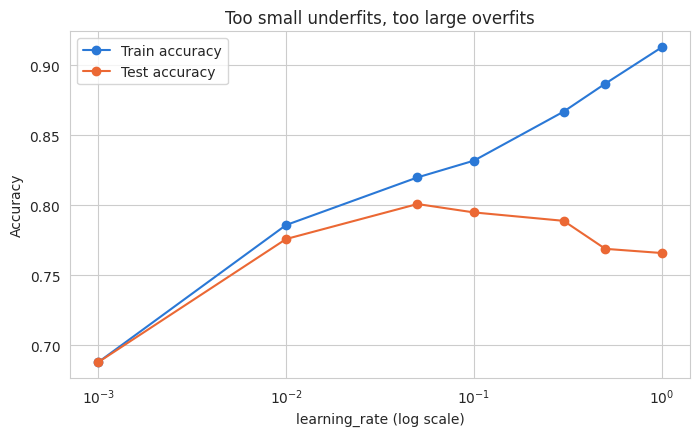

In [51]:
plt.figure(figsize=(8, 4.5))
plt.plot(lr_table['learning_rate'], lr_table['train_acc'], marker='o', label='Train accuracy', color='#2a78d6')
plt.plot(lr_table['learning_rate'], lr_table['test_acc'], marker='o', label='Test accuracy', color='#eb6834')
plt.xscale('log')
plt.xlabel('learning_rate (log scale)')
plt.ylabel('Accuracy')
plt.title('Too small underfits, too large overfits')
plt.legend()
plt.show()

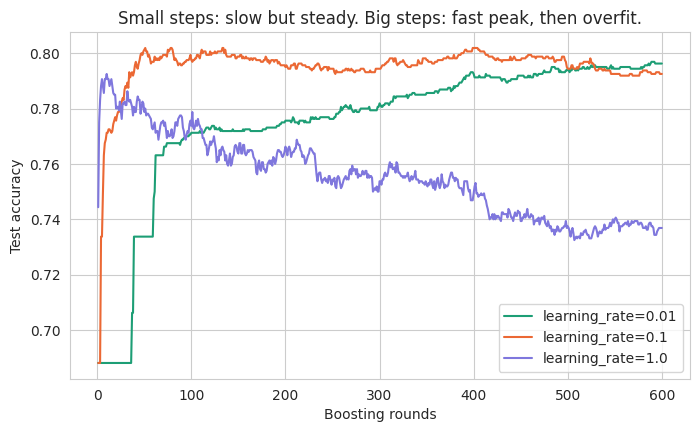

In [52]:
# The same story as learning curves: three learning rates, 600 rounds each
plt.figure(figsize=(8, 4.5))
for lr, colour in [(0.01, '#1D9E75'), (0.1, '#eb6834'), (1.0, '#7F77DD')]:
    m = GradientBoostingClassifier(n_estimators=600, learning_rate=lr, random_state=0).fit(X_train, y_train)
    curve = [(p == y_test).mean() for p in m.staged_predict(X_test)]
    plt.plot(range(1, 601), curve, label=f'learning_rate={lr}', color=colour)
plt.xlabel('Boosting rounds')
plt.ylabel('Test accuracy')
plt.title('Small steps: slow but steady. Big steps: fast peak, then overfit.')
plt.legend()
plt.show()

**Reading the picture:** `learning_rate=1.0` shoots up quickly, peaks within a handful of rounds, then declines as it memorises the training set. `0.01` is still climbing at 600 rounds - it needs far more trees. `0.1` is a sensible middle. This is the **learning_rate vs n_estimators trade-off**.

## The trade-off made concrete: same total movement, different step size
`learning_rate x n_estimators` roughly measures how far the model travels. Here we keep it about equal and vary the step size.

In [53]:
rows = []
for lr, n in [(1.0, 20), (0.3, 70), (0.1, 200), (0.03, 700)]:
    m = GradientBoostingClassifier(n_estimators=n, learning_rate=lr, max_depth=3, random_state=0).fit(X_train, y_train)
    rows.append({'learning_rate': lr, 'n_estimators': n, 'lr x n': round(lr * n, 1),
                 'train_acc': round(m.score(X_train, y_train), 3),
                 'test_acc': round(m.score(X_test, y_test), 3),
                 'test_auc': round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3)})
pd.DataFrame(rows)

,learning_rate,n_estimators,lr x n,train_acc,test_acc,test_auc
0,1.00,20,20.0,0.824,0.780,0.827
1,0.30,70,21.0,0.833,0.799,0.844
2,0.10,200,20.0,0.832,0.795,0.847
3,0.03,700,21.0,0.832,0.798,0.846


**Reading the table:** the big-step run (`learning_rate=1.0`, 20 rounds) ends clearly lowest, while the three smaller-step runs finish close together near the top. Smaller steps buy a little accuracy at the price of more trees, i.e. more training time.

## Early stopping - let the model decide how many rounds
Instead of guessing `n_estimators`, hold back a slice of the training data and **stop as soon as the score stops improving** for several rounds.

In [54]:
gb_es = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.1, max_depth=3,
                                    n_iter_no_change=10, validation_fraction=0.1, random_state=0).fit(X_train, y_train)
print('We allowed up to 1000 rounds, but it stopped at:', gb_es.n_estimators_)
print('Test accuracy:', round(gb_es.score(X_test, y_test), 3))

We allowed up to 1000 rounds, but it stopped at: 82
Test accuracy: 0.796


## max_depth - how strong should each weak learner be?
Boosting wants **weak** learners. Let's see what happens as the trees get deeper (200 rounds, learning rate 0.1).

In [55]:
rows = []
for d in [1, 2, 3, 5, 8]:
    m = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=d, random_state=0).fit(X_train, y_train)
    rows.append({'max_depth': d, 'train_acc': round(m.score(X_train, y_train), 3),
                 'test_acc': round(m.score(X_test, y_test), 3)})
depth_table = pd.DataFrame(rows)
depth_table

,max_depth,train_acc,test_acc
0,1,0.784,0.779
1,2,0.813,0.798
2,3,0.832,0.795
3,5,0.896,0.777
4,8,0.998,0.768


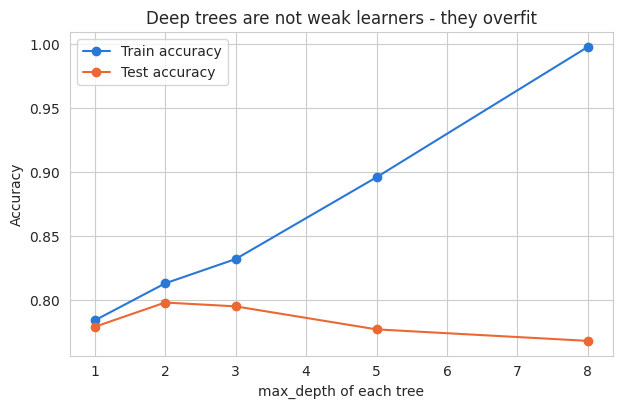

In [56]:
plt.figure(figsize=(7, 4.2))
plt.plot(depth_table['max_depth'], depth_table['train_acc'], marker='o', label='Train accuracy', color='#2a78d6')
plt.plot(depth_table['max_depth'], depth_table['test_acc'], marker='o', label='Test accuracy', color='#eb6834')
plt.xlabel('max_depth of each tree')
plt.ylabel('Accuracy')
plt.title('Deep trees are not weak learners - they overfit')
plt.legend()
plt.show()

## AdaBoost's learning rate too

In [57]:
rows = []
for lr in [0.05, 0.2, 0.5, 1.0]:
    m = AdaBoostClassifier(n_estimators=200, learning_rate=lr, random_state=0).fit(X_train, y_train)
    rows.append({'learning_rate': lr, 'train_acc': round(m.score(X_train, y_train), 3),
                 'test_acc': round(m.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,learning_rate,train_acc,test_acc
0,0.05,0.755,0.754
1,0.20,0.774,0.774
2,0.50,0.784,0.784
3,1.00,0.784,0.783


## A stress test: noisy labels - who overfits?
Real data contains **mislabelled rows**. Boosting is often warned about because it keeps concentrating on hard examples, and a mislabelled example looks like a "hard" one. Let us test it honestly: flip **30% of the TRAINING labels at random** (the test labels stay clean) and compare.

In [58]:
rng = np.random.default_rng(0)
flip = rng.random(len(y_train)) < 0.30
y_train_noisy = np.where(flip, 1 - y_train, y_train)

candidates = {
    'Random forest (deep trees)':               lambda: RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    'AdaBoost (stumps)':                         lambda: AdaBoostClassifier(n_estimators=300, learning_rate=1.0, random_state=0),
    'Gradient boosting (default, careful)':      lambda: GradientBoostingClassifier(random_state=0),
    'Gradient boosting (aggressive: lr=0.3, 300 trees)': lambda: GradientBoostingClassifier(n_estimators=300, learning_rate=0.3, random_state=0),
}
rows = []
for name, make in candidates.items():
    clean = make().fit(X_train, y_train).score(X_test, y_test)
    noisy = make().fit(X_train, y_train_noisy).score(X_test, y_test)
    rows.append({'model': name, 'test_acc (clean labels)': round(clean, 3),
                 'test_acc (30% noisy labels)': round(noisy, 3), 'drop': round(clean - noisy, 3)})
pd.DataFrame(rows).set_index('model')

,test_acc (clean labels),test_acc (30% noisy labels),drop
model,,,
Random forest (deep trees),0.785,0.698,0.087
AdaBoost (stumps),0.782,0.771,0.011
"Gradient boosting (default, careful)",0.797,0.784,0.013
"Gradient boosting (aggressive: lr=0.3, 300 trees)",0.789,0.705,0.084


**What this shows:** it is **not** simply "boosting is fragile, bagging is robust". The models that suffer are the ones with **a lot of capacity or an aggressive step size** - the deep-tree random forest, which can memorise the flipped labels, and gradient boosting run with a big learning rate and many deep-ish trees. **Weak learners combined with small careful steps** (AdaBoost with stumps, default gradient boosting) stay robust. The lesson: *overfitting is controlled by how much capacity you give the model and how fast you let it learn*, in either family.

---
# Part 6 - Boosting for REGRESSION
Predicting `monthly_watch_hours` (a number). Gradient boosting works exactly as in Part 4 (fit the residuals). **AdaBoostRegressor** (AdaBoost.R2) re-weights hard examples too, then combines trees using a weighted median.

In [59]:
rf_reg = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X_train, yh_train)
ada_reg = AdaBoostRegressor(n_estimators=100, random_state=0).fit(X_train, yh_train)
gb_reg = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=0).fit(X_train, yh_train)
tree_reg = DecisionTreeRegressor(random_state=0).fit(X_train, yh_train)

rows = []
for name, m in [('Single tree (no limits)', tree_reg), ('Random forest (200 trees)', rf_reg),
                ('AdaBoost regressor (100)', ada_reg), ('Gradient boosting (200 trees, depth 3)', gb_reg)]:
    p = m.predict(X_test)
    rows.append({'model': name, 'train_R2': round(m.score(X_train, yh_train), 3),
                 'test_R2': round(r2_score(yh_test, p), 3),
                 'MAE_hours': round(mean_absolute_error(yh_test, p), 2),
                 'RMSE_hours': round(float(np.sqrt(mean_squared_error(yh_test, p))), 2)})
pd.DataFrame(rows).set_index('model')

,train_R2,test_R2,MAE_hours,RMSE_hours
model,,,,
Single tree (no limits),1.000,0.650,4.22,5.27
Random forest (200 trees),0.976,0.825,2.95,3.73
AdaBoost regressor (100),0.810,0.800,3.16,3.98
"Gradient boosting (200 trees, depth 3)",0.868,0.843,2.80,3.52


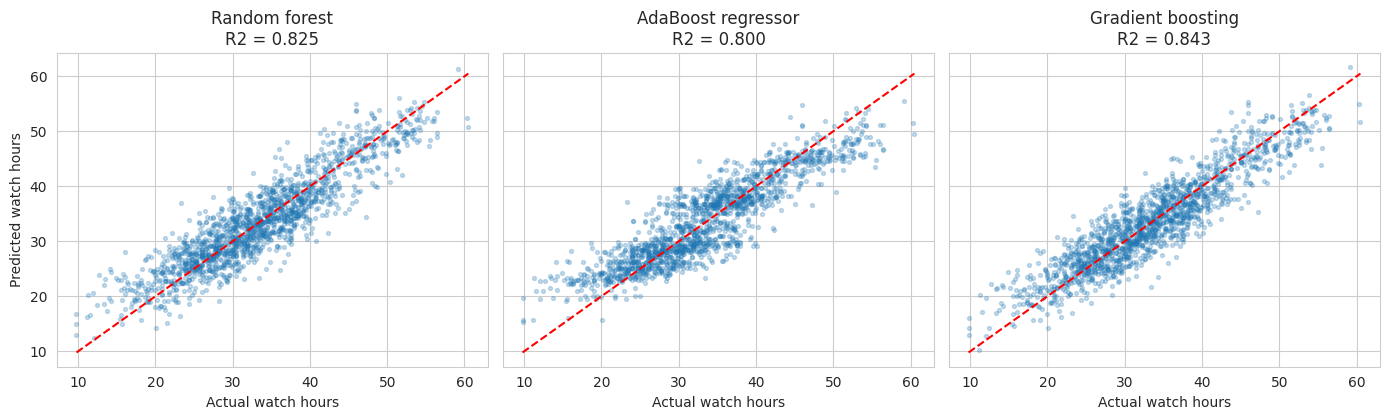

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, [('Random forest', rf_reg), ('AdaBoost regressor', ada_reg), ('Gradient boosting', gb_reg)]):
    p = m.predict(X_test)
    ax.scatter(yh_test, p, alpha=0.25, s=8)
    lims = [yh_test.min(), yh_test.max()]
    ax.plot(lims, lims, color='red', linestyle='--')
    ax.set_title(f'{name}\nR2 = {r2_score(yh_test, p):.3f}')
    ax.set_xlabel('Actual watch hours')
axes[0].set_ylabel('Predicted watch hours')
plt.tight_layout()
plt.show()

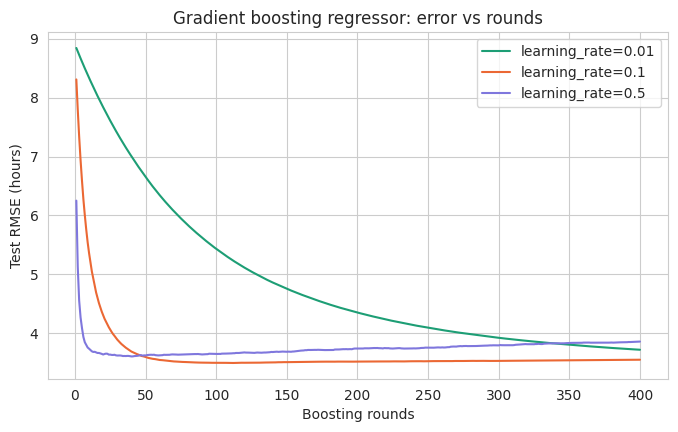

In [61]:
# Learning rate matters for regression too: test RMSE round by round
plt.figure(figsize=(8, 4.5))
for lr, colour in [(0.01, '#1D9E75'), (0.1, '#eb6834'), (0.5, '#7F77DD')]:
    m = GradientBoostingRegressor(n_estimators=400, learning_rate=lr, max_depth=3, random_state=0).fit(X_train, yh_train)
    curve = [np.sqrt(mean_squared_error(yh_test, p)) for p in m.staged_predict(X_test)]
    plt.plot(range(1, 401), curve, label=f'learning_rate={lr}', color=colour)
plt.xlabel('Boosting rounds')
plt.ylabel('Test RMSE (hours)')
plt.title('Gradient boosting regressor: error vs rounds')
plt.legend()
plt.show()

---
## Note: Bagging vs Boosting - the summary

| | Bagging / Random Forest | Boosting |
|---|---|---|
| Idea | many **independent** strong-but-unstable models, averaged | many **dependent** weak models, each fixing the last |
| Fixes mainly | variance | bias (and variance, if tuned) |
| Weak/strong learners | deep trees | shallow trees / stumps |
| Combination | equal vote or average | weighted sum |
| Parallel? | yes | no - sequential |
| Tuning difficulty | forgiving; more trees rarely hurts | needs care: learning_rate, n_estimators, depth interact |
| Overfitting risk | low | moderate - control with small learning rate, shallow trees, early stopping |
| Analogy | independent panel voting | revision rounds after each mock test |

**Which to use?** Random forest is a fast, forgiving first choice. Boosting often squeezes out a bit more accuracy but rewards careful tuning.

## Recap
- **Boosting:** build weak learners **sequentially**, each focusing on the previous models' errors; combine with a weighted sum.
- **AdaBoost:** re-weight the examples (wrong ones get heavier); each stump's say `alpha = 0.5 ln((1 - err)/err)`; final answer = weighted vote.
- **Gradient boosting:** start from a simple guess, repeatedly fit a small tree to the **residuals** (negative gradient of the loss) and add `learning_rate x tree`. Classification does this on log-odds with pseudo-residuals.
- **Hyperparameters:** `n_estimators`, **`learning_rate`** (small = needs more trees, usually better), `max_depth` (keep weak/shallow). Early stopping picks the number of rounds for you.
- **Bagging vs boosting:** parallel + variance reduction vs sequential + bias reduction. Overfitting depends on capacity and aggressiveness, not just the family.
- Next class (Boosting II) builds on exactly this idea.

---

## Assignment
1. Fix both `# FIX ME` bugs and re-run from the top. Report what the weight on mistakes becomes after the AdaBoost fix, and the from-scratch GB's final test RMSE vs scikit-learn's.
2. **Tune learning_rate:** with `n_estimators=200`, find the learning rate with the best TEST accuracy. Explain, using train vs test accuracy, why very small and very large values are worse.
3. Pick the best `max_depth` for Gradient Boosting and explain why deep trees hurt a boosting model.
4. Build a comparison table of Random Forest, AdaBoost and Gradient Boosting (accuracy, recall, AUC). Which would you pick, and is the difference large enough to matter?
5. In your own words: **why do AdaBoost's weights on misclassified customers go UP after each round?** And why does Gradient Boosting fit the residuals instead of the original target?
6. In your own words: bagging vs boosting - give two differences and one situation where you would prefer each.
